Эпизод 1

In [2]:
import pandas as pd


file_path = 'transactions.csv'


df = pd.read_csv(file_path, sep=',', index_col=0)


top3 = (
    df[df['STATUS'] == 'OK']
    .sort_values('SUM', ascending=False)
    .head(3)
)

print("Задача 1: топ-3 платежа")
for _, row in top3.iterrows():
    
    print(f"  {row['CONTRACTOR']}: {int(row['SUM'])}")


total = df[(df['STATUS'] == 'OK') & (df['CONTRACTOR'] == 'Umbrella, Inc')]['SUM'].sum()
print(f"\nЗадача 2: сумма платежей в Umbrella, Inc = {int(total)}")

Задача 1: топ-3 платежа
  Acme, Inc: 100500
  Umbrella, Inc: 1000
  Umbrella, Inc: 999

Задача 2: сумма платежей в Umbrella, Inc = 925719


Эпизод 2

Статистика по авиакомпаниям:
 CARGO  flights_count  total_price  total_weight
 Jumbo             50        76795         18709
Medium            100        36312          9507
Nimble            500       752588          7545
--------------------------------------------------


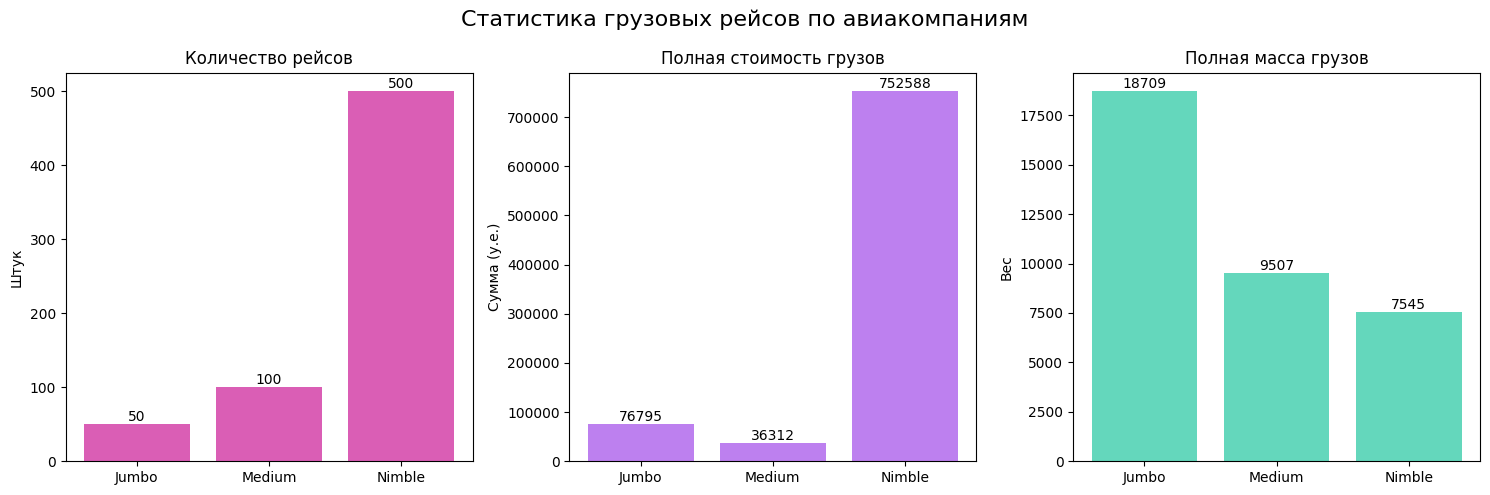

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('flights.csv', sep=',', index_col=0)

stats = df.groupby('CARGO').agg(
    flights_count=('PRICE', 'count'),
    total_price=('PRICE', 'sum'),
    total_weight=('WEIGHT', 'sum')
).reset_index()

print("Статистика по авиакомпаниям:")
print(stats.to_string(index=False))
print("-" * 50)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Статистика грузовых рейсов по авиакомпаниям', fontsize=16)

colors = ["#DA5EB5", "#BD80EF", "#64D7BC"]

axes[0].bar(stats['CARGO'], stats['flights_count'], color=colors[0])
axes[0].set_title('Количество рейсов')
axes[0].set_ylabel('Штук')
axes[0].bar_label(axes[0].containers[0])

axes[1].bar(stats['CARGO'], stats['total_price'], color=colors[1])
axes[1].set_title('Полная стоимость грузов')
axes[1].set_ylabel('Сумма (у.е.)')
axes[1].bar_label(axes[1].containers[0], fmt='%.0f')

axes[2].bar(stats['CARGO'], stats['total_weight'], color=colors[2])
axes[2].set_title('Полная масса грузов')
axes[2].set_ylabel('Вес')
axes[2].bar_label(axes[2].containers[0], fmt='%.0f')

plt.tight_layout()
plt.show()

3 Эпизод

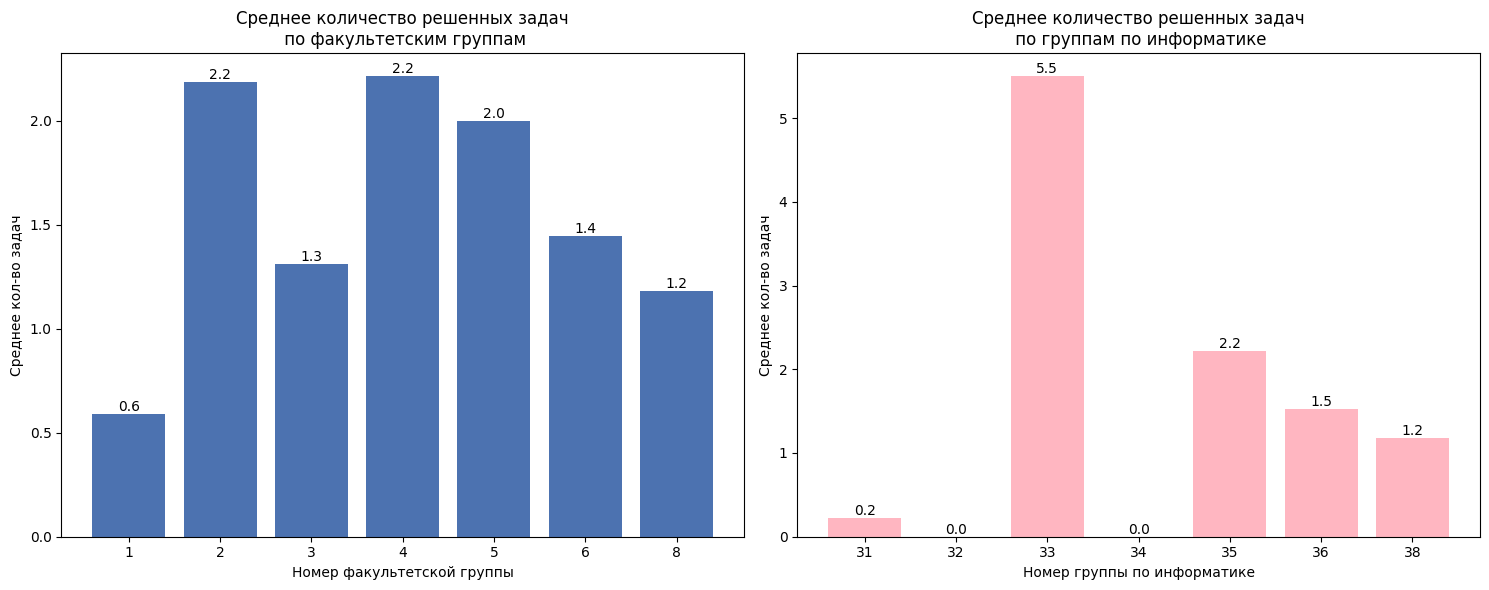


Результаты по задаче 2:
Студенты, прошедшие более одного теста хотя бы в одной задаче (G или H):
   login  group_faculty  group_out    G    H
r0300205              2         33 30.0 49.0
r0300206              2         33 30.0 49.0
r0300209              2         33  0.0 30.0
r0300212              2         36  0.0 20.0
r0300301              3         35  8.0 23.0
r0300314              3         33  9.0 20.0
r0300508              5         33 29.0  0.0
r0300511              5         35  0.0 29.0
r0300514              5         33  0.0 30.0
r0300515              5         35  0.0 25.0

Факультетские группы (group_faculty):
group_faculty
2    4
3    2
5    4

Группы по информатике (group_out):
group_out
33    6
35    3
36    1


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup


students = pd.read_excel('students_info.xlsx')
students = students.dropna(subset=['login'])


with open('results_ejudge.html', 'r', encoding='windows-1251') as f:
    soup = BeautifulSoup(f, 'html.parser')

table = soup.find('table', class_='standings')


rows = table.find_all('tr')

headers = [th.text.strip() for th in rows[0].find_all('th')]


data = []
for row in rows[1:]:
    cells = row.find_all('td')
    if not cells:
        continue

    row_data = [cell.text.strip().replace('\xa0', '') for cell in cells]
    data.append(row_data)


ejudge = pd.DataFrame(data, columns=headers)


ejudge = ejudge.rename(columns={'User': 'login'})


ejudge = ejudge[['login', 'Solved', 'G', 'H']]


df = pd.merge(students, ejudge, on='login', how='inner')



df['Solved'] = pd.to_numeric(df['Solved'], errors='coerce')


avg_by_faculty = df.groupby('group_faculty')['Solved'].mean().sort_index()
avg_by_out = df.groupby('group_out')['Solved'].mean().sort_index()


fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].bar(avg_by_faculty.index.astype(str), avg_by_faculty.values, color='#4C72B0')
axes[0].set_title('Среднее количество решенных задач\n по факультетским группам')
axes[0].set_xlabel('Номер факультетской группы')
axes[0].set_ylabel('Среднее кол-во задач')
axes[0].bar_label(axes[0].containers[0], fmt='%.1f')

axes[1].bar(avg_by_out.index.astype(str), avg_by_out.values, color='#FFB6C1')
axes[1].set_title('Среднее количество решенных задач\n по группам по информатике')
axes[1].set_xlabel('Номер группы по информатике')
axes[1].set_ylabel('Среднее кол-во задач')
axes[1].bar_label(axes[1].containers[0], fmt='%.1f')

plt.tight_layout()
plt.show()



df['G'] = pd.to_numeric(df['G'], errors='coerce').fillna(0)
df['H'] = pd.to_numeric(df['H'], errors='coerce').fillna(0)


df['G_tests'] = (df['G'] / 10).astype(int)
df['H_tests'] = (df['H'] / 10).astype(int)


winners = df[(df['G_tests'] > 1) | (df['H_tests'] > 1)]

print("\nРезультаты по задаче 2:")
print("Студенты, прошедшие более одного теста хотя бы в одной задаче (G или H):")
print(winners[['login', 'group_faculty', 'group_out', 'G', 'H']].to_string(index=False))

print("\nФакультетские группы (group_faculty):")
print(winners['group_faculty'].value_counts().sort_index().to_string())

print("\nГруппы по информатике (group_out):")
print(winners['group_out'].value_counts().sort_index().to_string())